Encontrados 4 arquivos DXF. 

Arquivo: viga_Z_definitiva_de_verdade


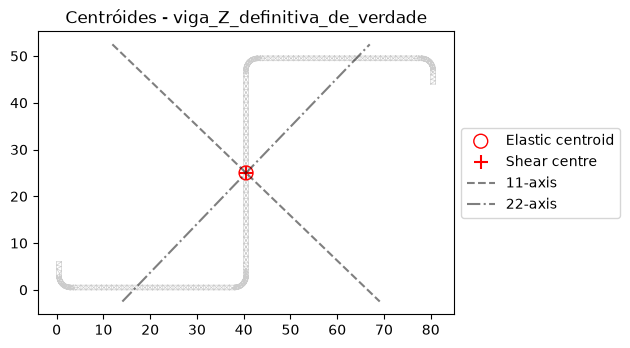

Arquivo: Seção_J


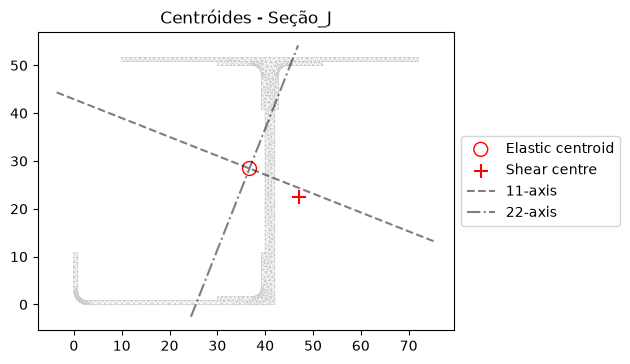

Arquivo: viga_C_definitiva


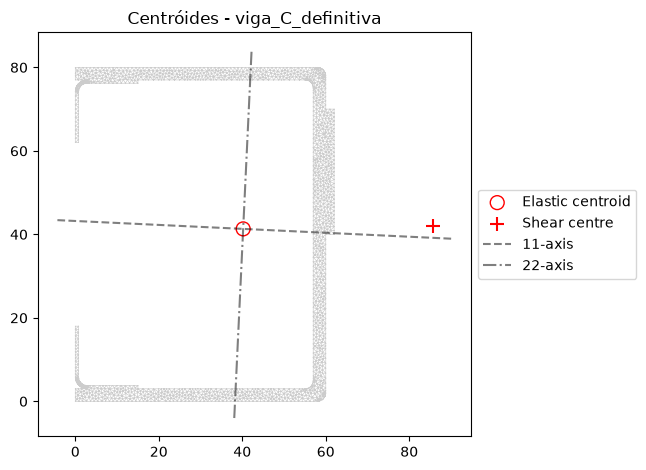

Arquivo: Seção_J_crippling


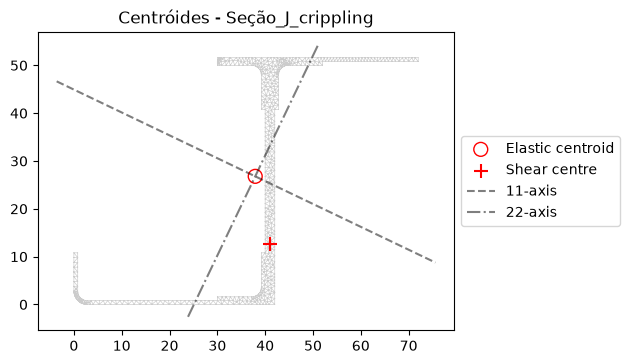

                                     Propriedades das Seções                                      
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Propriedade ┃ viga_Z_definitiva_de_verdade ┃   Seção_J ┃ viga_C_definitiva ┃ Seção_J_crippling ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ A           │                       135.73 │    239.09 │            687.09 │            223.05 │
│ x_centroide │                       40.501 │    36.718 │            40.215 │            37.919 │
│ y_centroide │                       25.001 │    28.431 │            41.310 │            26.794 │
│ I_xx_c      │                     60428.18 │ 100227.32 │         701139.04 │          91310.84 │
│ I_yy_c      │                     56799.34 │  42856.77 │         305215.75 │          37527.60 │
│ I_xy_c      │                     46649.23 │  26825.71 │          18706.97 │          33362.33 │
│ I_qsi_c     │                    105298.26 │ 110816.26 │         702020.96 │         107270.18 │
│ I_eta_c     │                     11929.25 │  32267.83 │         304333.83 │          21568.27 │
│ x_se        │                        40.50 │     47.04 │             85.75 │             41.06 │
│ y_se        │                        25.00 │     22.56 │             41.97 │             12.63 │
│ phi         │                       -43.89 │    -21.54 │             -2.70 │            -25.56 │
└─────────────┴──────────────────────────────┴───────────┴───────────────────┴───────────────────┘

In [3]:
from pathlib import Path
from rich.console import Console
from rich.table import Table
from sectionproperties.analysis import Section
from sectionproperties.pre import Geometry
from shapely.geometry import LineString
from shapely.ops import linemerge, polygonize
import ezdxf
import ezdxf.path

# 1. Caminho dos arquivos dxf
pasta_dxfs = Path("Secoes_dxf")

# 2. Pega todos os arquivos .dxf da pasta
dxf_paths = list(pasta_dxfs.glob("*.dxf"))

if not dxf_paths:
    print("Nenhum arquivo DXF encontrado.")
else:
    print(f"Encontrados {len(dxf_paths)} arquivos DXF. \n")

table = Table(title="Propriedades das Seções")
table.add_column("Propriedade", justify="left", style="cyan", no_wrap=True)

Propriedades = {}

# 3. Loop para cada dxf
for dxf_filepath in dxf_paths:
    nome_sec = dxf_filepath.stem
    print(f"==========================================")
    print(f"Arquivo: {nome_sec}")
    print(f"==========================================")
        
    try:
        doc = ezdxf.readfile(dxf_filepath)
        msp = doc.modelspace()
        
        linhas_avulsas = []
        
        # Extração de pontos do DXF
        for entity in msp:
            if entity.dxftype() in ['LWPOLYLINE', 'POLYLINE', 'SPLINE', 'ARC', 'LINE', 'CIRCLE', 'ELLIPSE']:
                try:
                    path = ezdxf.path.make_path(entity)
                    pts = []
                    # Achata as curvas (fillets) com precisão de 0.01 mm
                    for v in path.flattening(distance=0.01): 
                        pts.append((round(v.x, 4), round(v.y, 4)))
                    
                    if len(pts) > 1:
                        linhas_avulsas.append(LineString(pts))
                except Exception as e:
                    print(f"Aviso ao processar entidade {entity.dxftype()}: {e}")
        
        # Topologia: união de linhas e criação de polígono via Shapely
        linha_mestra = linemerge(linhas_avulsas)
        poligonos_fechados = list(polygonize(linha_mestra))
        
        if not poligonos_fechados:
            raise ValueError("As linhas no DXF não formam um contorno fechado.")
            
        poligono_principal = max(poligonos_fechados, key=lambda p: p.area)
        
        # Extrai os pontos (removendo o último ponto duplicado do Shapely)
        pontos_ordenados = list(poligono_principal.exterior.coords)[:-1]

        # Formatação matemática oficial exigida pela classe Geometry do sectionproperties
        qtd_pontos = len(pontos_ordenados)
        facets = [(i, (i + 1) % qtd_pontos) for i in range(qtd_pontos)]
        
        ponto_interno = poligono_principal.representative_point()
        control_points = [[ponto_interno.x, ponto_interno.y]]
        
        # Cria a geometria
        geom = Geometry.from_points(
            points=pontos_ordenados,
            facets=facets,
            control_points=control_points
        )
        
        # NOTA: A linha 'geom = geom.clean_geometry()' foi removida daqui.

        # Gera a malha e cria a seção (Uso oficial da API)
        geom.create_mesh(mesh_sizes=[0.5])
        sec = Section(geometry=geom)
        
        # Calcula propriedades (Métodos oficiais)
        sec.calculate_geometric_properties()
        sec.calculate_warping_properties()

        # Armazena resultados (Usando os getters oficiais documentados)
        Propriedades[nome_sec] = {
            "A": f"{sec.get_area():.2f}",
            "x_centroide": f"{sec.get_c()[0]:.3f}",
            "y_centroide": f"{sec.get_c()[1]:.3f}",        
            "I_xx_c": f"{sec.get_ic()[0]:.2f}",
            "I_yy_c": f"{sec.get_ic()[1]:.2f}",
            "I_xy_c": f"{sec.get_ic()[2]:.2f}",
            "I_qsi_c": f"{sec.get_ip()[0]:.2f}",
            "I_eta_c": f"{sec.get_ip()[1]:.2f}",
            "x_se": f"{sec.get_sc()[0]:.2f}",  
            "y_se": f"{sec.get_sc()[1]:.2f}",
            "phi": f"{sec.get_phi():.2f}",    
        }

        # Gráfico
        sec.plot_centroids(title=f"Centróides - {dxf_filepath.stem}", alpha=0.2)
        
    except Exception as e:
        import traceback
        print(f"ERRO ao processar a seção '{nome_sec}': {e}")
        print("Pulando para o próximo arquivo...\n")
        continue

# Geração da Tabela
if Propriedades:
    nomes_secoes = list(Propriedades.keys())
    lista_propriedades = list(Propriedades[nomes_secoes[0]].keys())

    for nome_sec in nomes_secoes:
        table.add_column(nome_sec, justify="right", style="green")

    for prop in lista_propriedades:
        linha_dados = [prop]
        for nome_sec in nomes_secoes:
            valor = Propriedades[nome_sec][prop]
            linha_dados.append(valor)
        table.add_row(*linha_dados)

    console = Console()
    console.print(table)
else:
    print("Não foi possível calcular as propriedades de nenhuma seção.")
